# histo2mri demo: registering a section

One call registers one histology section to its MRI:

```python
from histo2mri import register_section
info = register_section(bids_root, subject, sample, out_dir)
```

This notebook runs that call on a NextBrain section and looks at what it wrote: the QC
figures and the transform. The steps inside the call are not shown here;
[demo_pipeline_steps.ipynb](demo_pipeline_steps.ipynb) unrolls them.

## 0. Setup

Imports the package from the repository root, so the notebook runs without installing it,
and sends the package log messages (the same ones that go into `<section>_process.log`) to
the notebook output.

In [1]:
import logging
import os
import sys

import numpy as np
from IPython.display import display
from PIL import Image

# Repository root = the parent of notebook/, so `import histo2mri` works uninstalled.
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import histo2mri
from histo2mri import PROFILES, register_section

print("histo2mri", histo2mri.__version__, "from:", os.path.relpath(os.path.dirname(histo2mri.__file__)))
print("profiles :", list(PROFILES))

histo2mri 0.1.0a1 from: ../histo2mri
profiles : ['default', 'he-cblock']


In [2]:
import warnings

# skimage 0.26 deprecates binary_dilation; the call is inside the package, and the warning
# is noise here. Remove this once preprocessing uses morphology.dilation.
warnings.filterwarnings("ignore", message=".*binary_dilation.*")

_pkg_logger = logging.getLogger("histo2mri")
for _h in list(_pkg_logger.handlers):
    _pkg_logger.removeHandler(_h)
_handler = logging.StreamHandler(sys.stdout)
_handler.setFormatter(logging.Formatter("%(levelname)s %(name)s: %(message)s"))
_pkg_logger.addHandler(_handler)
_pkg_logger.setLevel(logging.INFO)
_pkg_logger.propagate = False

## 1. The section

This demo uses one publicly available section:

> **NextBrain** - Iglesias Gonzalez, Casamitjana, Atzeni, Billot, Thomas, Blackburn et al.,
> *Registered histology, MRI, and manual annotations of over 300 brain regions in 5 human
> hemispheres*, University College London, 2023.
> [doi:10.5522/04/24243835.v1](https://doi.org/10.5522/04/24243835.v1), CC0-1.0.
>
> Subject **NB_EX9-19**, block **P2.3**, section **06**, H&E stain.

The data is not shipped with the package; the README describes the BIDS layout it is read
from, in which this section is `sub-NBEX919` / `sample-P2306` / `stain-HE`. Point
`HISTO2MRI_BIDS` at your own dataset, or edit `BIDS_ROOT` below.

In [3]:
BIDS_ROOT = os.environ.get("HISTO2MRI_BIDS", os.path.join("..", "..", "data", "bids"))
SUBJECT = "NBEX919"               # sub-NBEX919  (NextBrain NB_EX9-19)
SAMPLE = "P2306"                  # sample-P2306 (block P2.3, section 06)
STAIN = "HE"                      # optional; needed only when a sample has several stains
OUT_DIR = os.path.join("..", "results", "demo_call_registration_pipeline")

print("BIDS root:", BIDS_ROOT)
print("output   :", OUT_DIR)

BIDS root: ../../data/bids
output   : ../results/demo_call_registration_pipeline


## 2. The call

`register_section` runs the whole registration and writes its outputs into `out_dir`. The
keyword arguments are the defaults of the command line; the two changed here are the ones
NextBrain sections need: `ransac_sample_size=3` because these sections give few matches, and
`mri_on_histo_tile_size=2048` because the histology is 4 um, so the default 348-pixel
checkerboard tile would be invisibly small.

Everything else - the cutting plane, the in-plane rotation, the flip and the pixel size -
comes from the BIDS sidecars, so nothing about the geometry is passed in here. It takes a
few minutes on a GPU; `device="cpu"` works but is much slower. Errors are not caught inside,
so a section that cannot be registered raises here.

INFO histo2mri.pipeline: Process started


INFO histo2mri.pipeline: Profile: default {'outlier_plane_dist': 20.0, 'outlier_knn': {'k': 8, 'plane_mad_k': 3.0, 'tukey_k': 3.0, 'cc_radius_scale': 3.0}, 'refine_similarity_weights': (1.0, 0.0)}


INFO histo2mri.pipeline: Loaded section sub-NBEX919_sample-P2306_stain-HE: coronal, rotation 0 deg, flip (True, False, False), spacing (0.004, 0.004, 0.004) mm


INFO histo2mri.pipeline: Prepared histology - proc_Ih size:(128, 128, 1)


INFO histo2mri.pipeline: Prepared MRI slab - slab_Im size:(220, 340, 450)


INFO histo2mri.pipeline: Best scale: 1.2999999523162842 score:0.9834330081939697


... (4 outputs left out)

INFO histo2mri.pipeline: Best patch:64 hist_stride:32 mri_stride:4 z_center:252


INFO histo2mri.pipeline: Fine matching z window: +/-60 slices (+/-24 mm)


INFO histo2mri.outliers: Outlier filter: removed 2, kept 10 matches


INFO histo2mri.pipeline: Fine matching - clean_matches:10


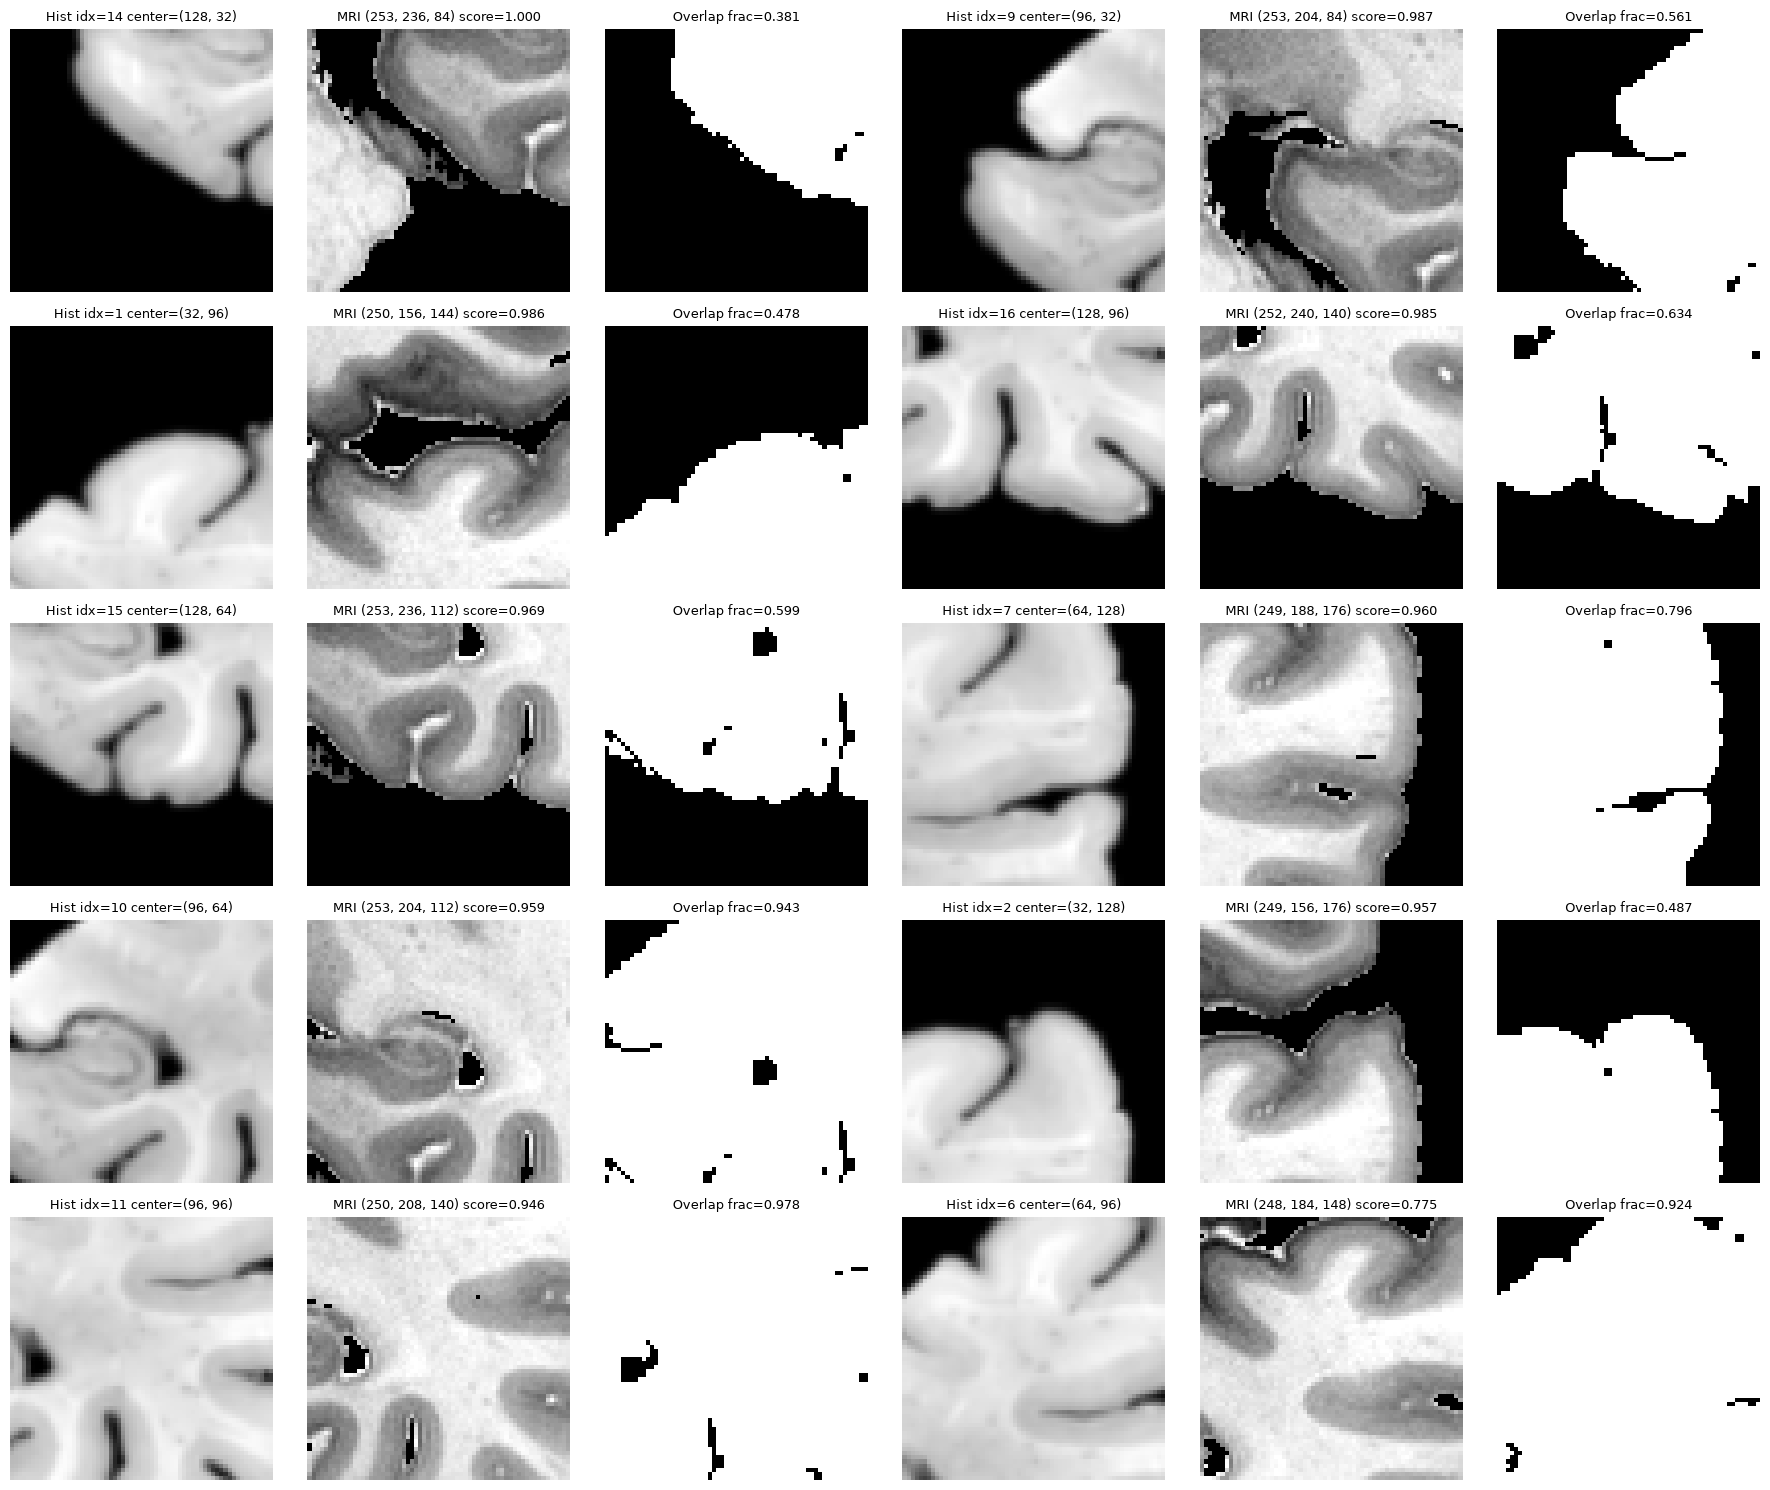

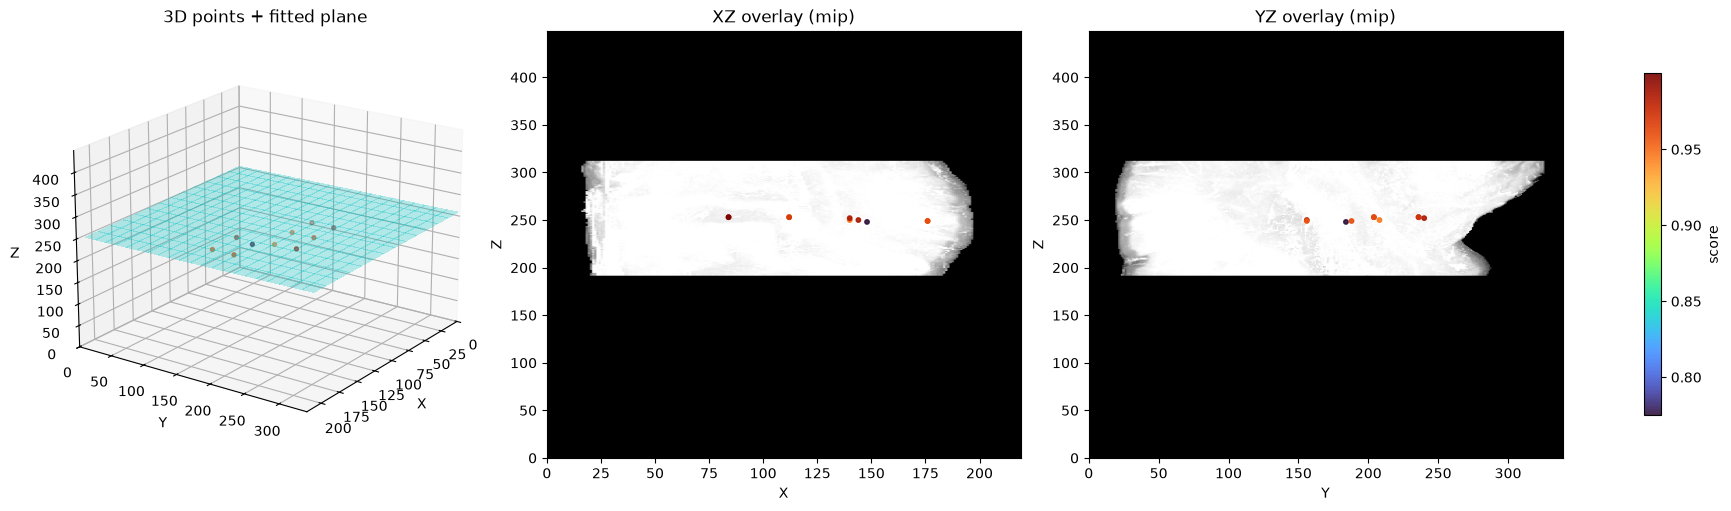

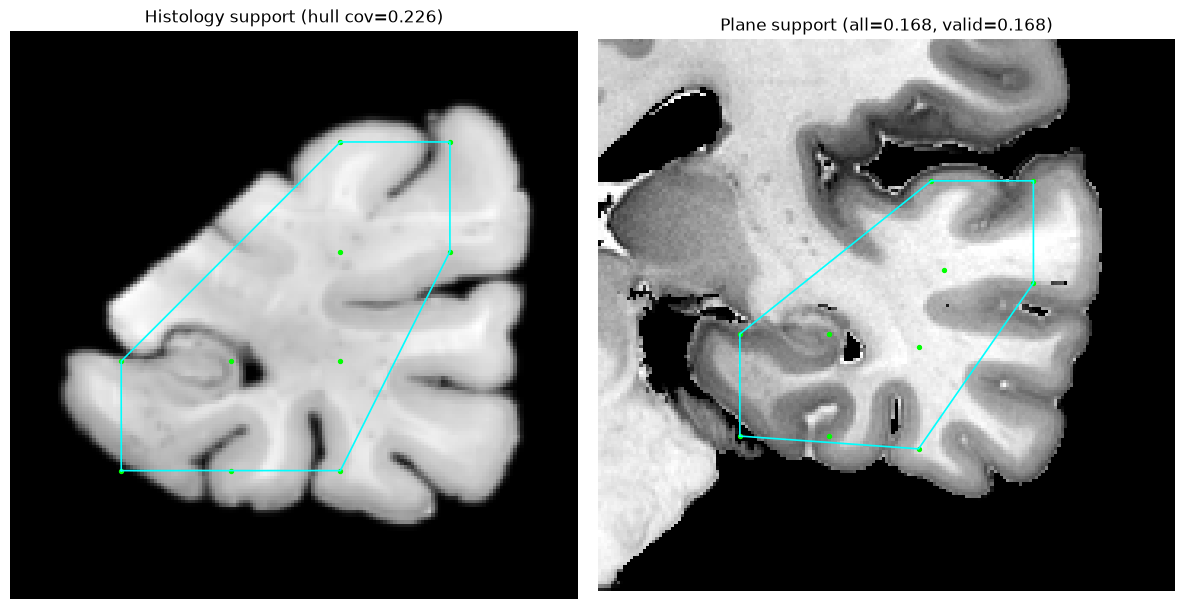

INFO histo2mri.pipeline: Common canvas - hist_common:(173, 181)


INFO histo2mri.pipeline: Fitted initial in-plane G


WARNING histo2mri.tps: RANSAC TPS: no valid hypothesis found; falling back to all points.


INFO histo2mri.pipeline: Init DDF - adaptive inlier_thresh=3.00, sample_size=3


INFO histo2mri.pipeline: Init DDF - in-plane filter: kept 8/8 (max in-plane 4.4 vox)


INFO histo2mri.pipeline: Init DDF - per-section clamp_vox=8.00 (kept |dxyz| max=4.6 vox)


INFO histo2mri.pipeline: Initial TPS on top of G fitted


INFO histo2mri.pipeline: Refined curved sheet


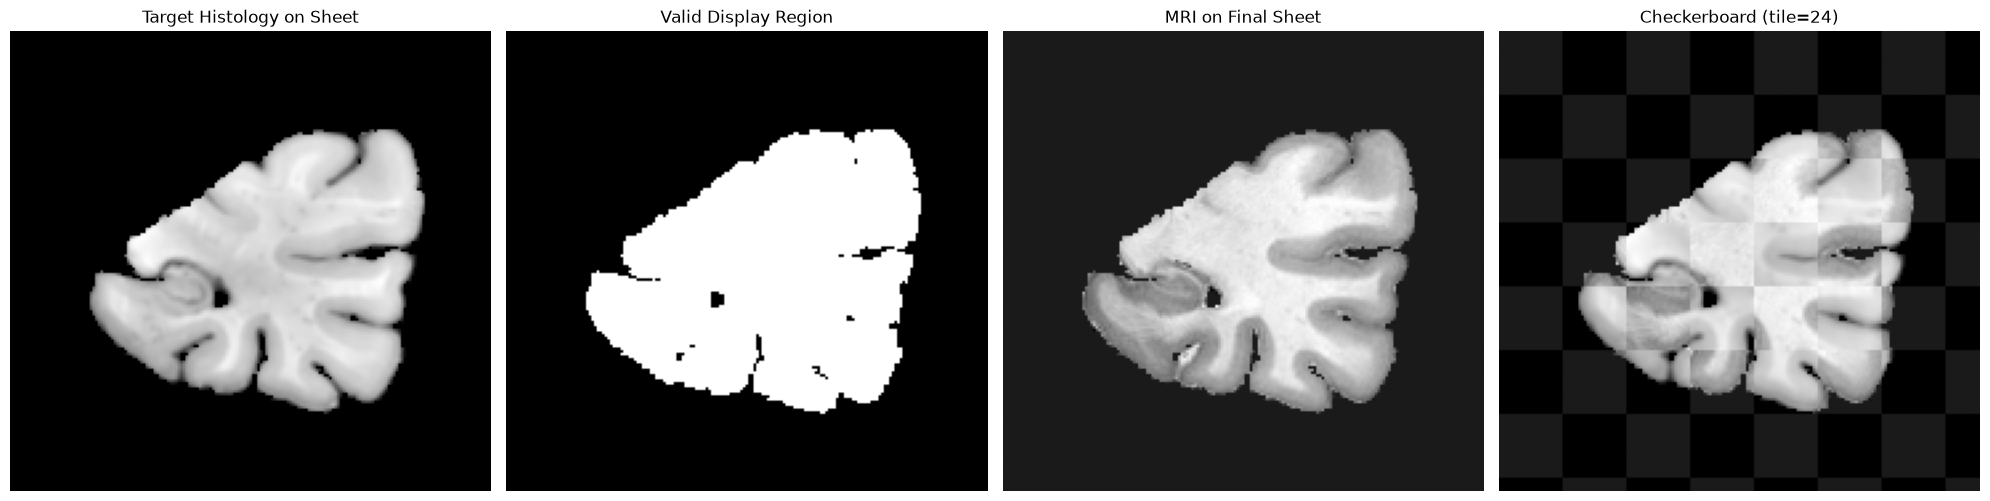

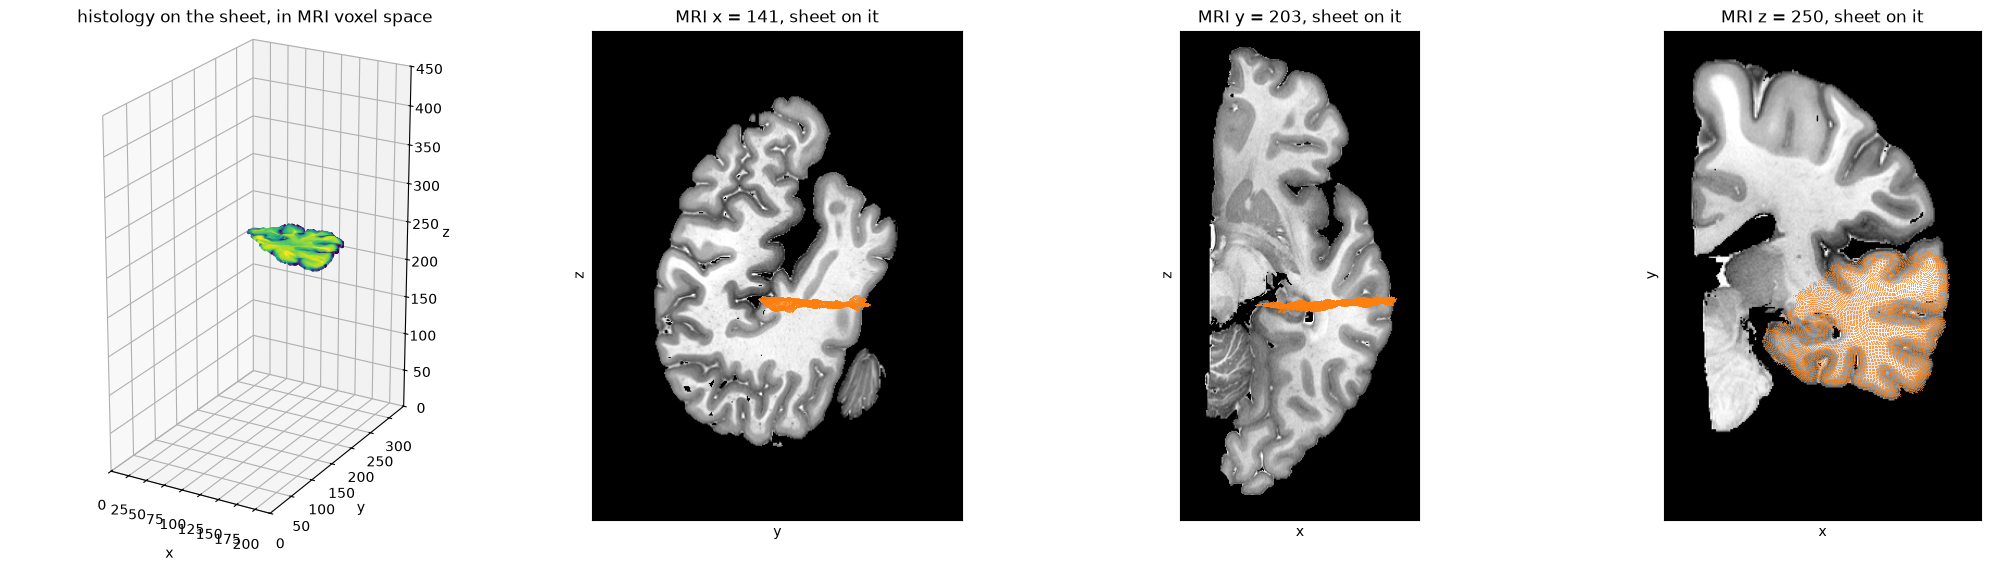

INFO histo2mri.pipeline: Composed A_common_to_hr


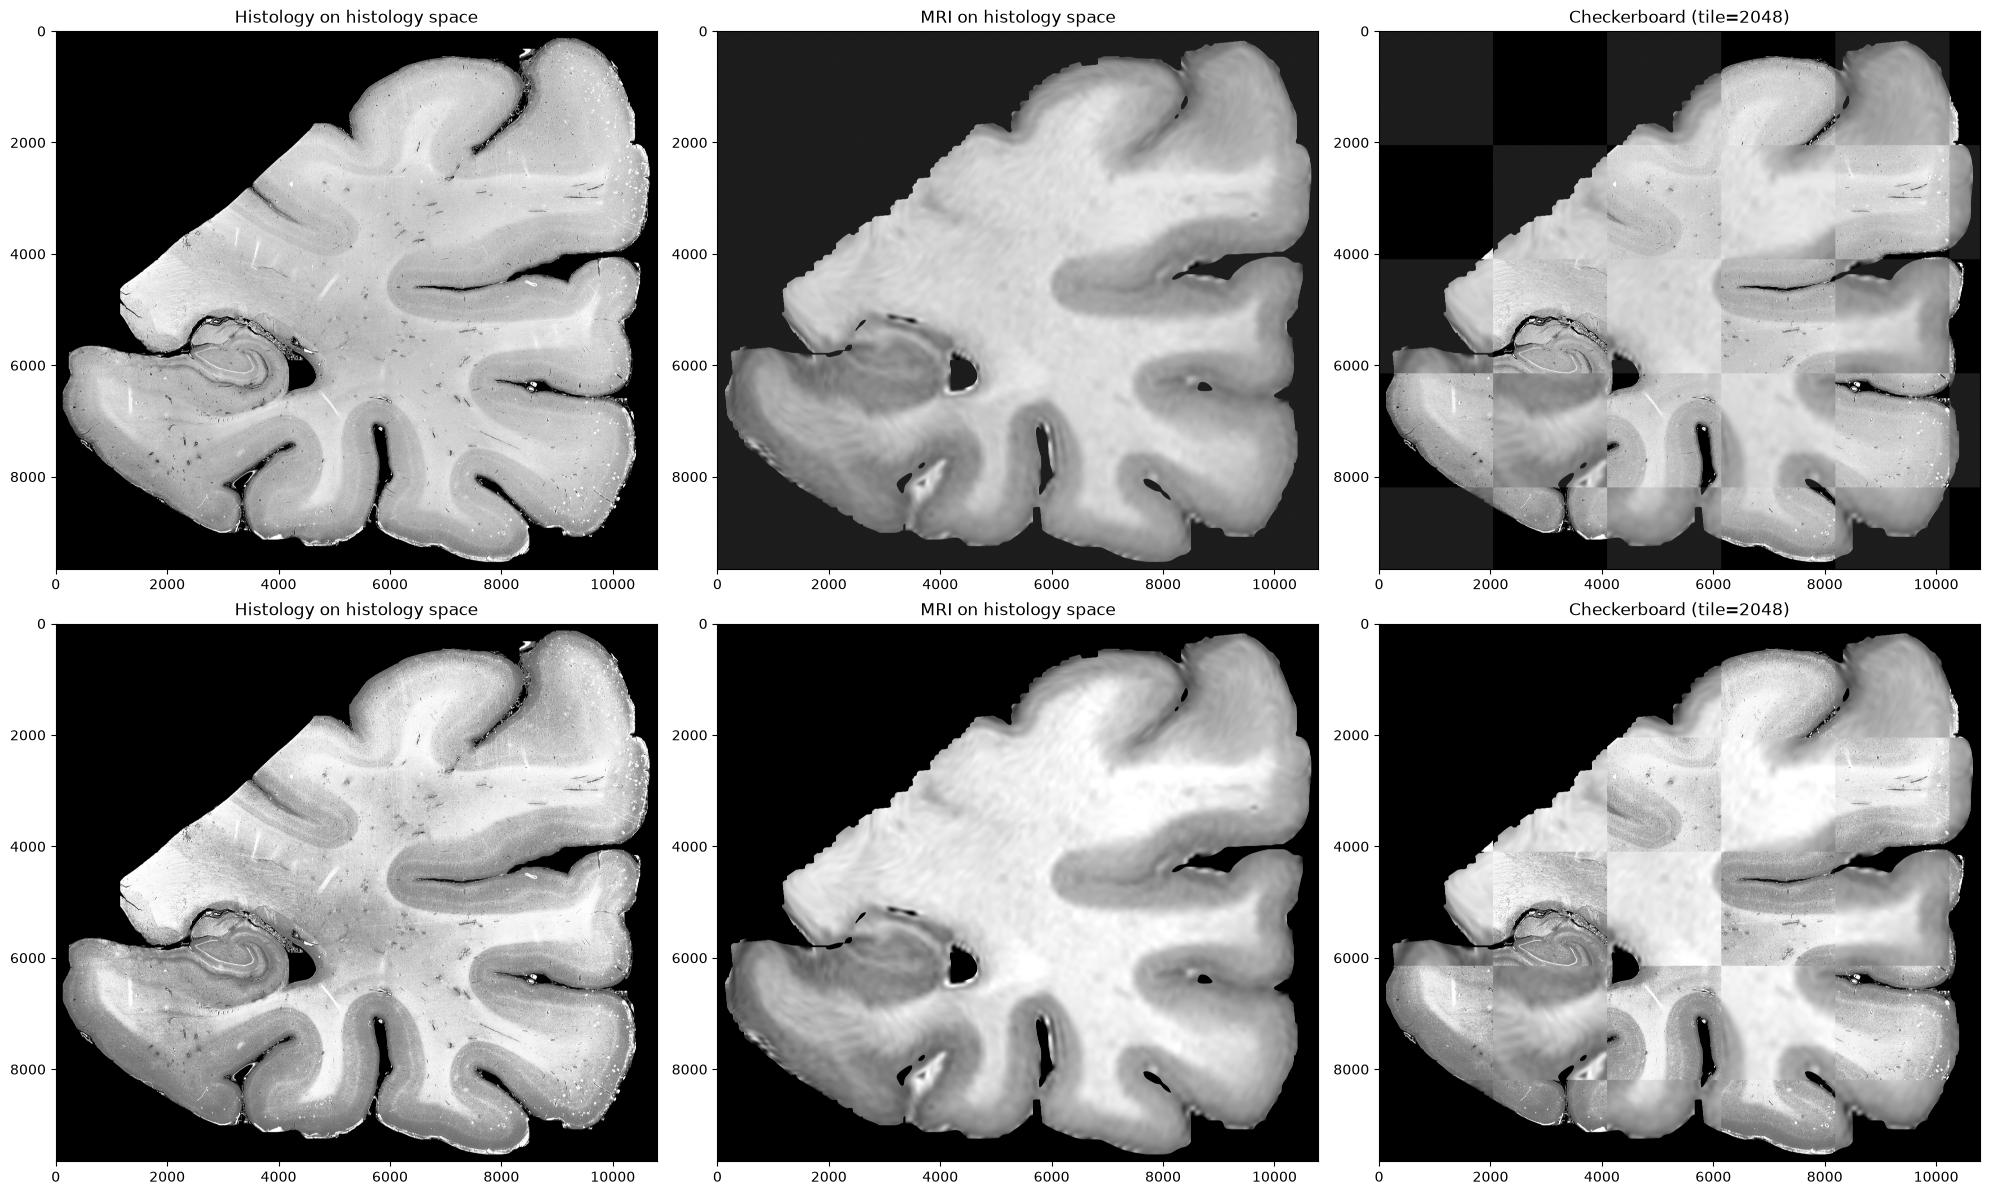

INFO histo2mri.pipeline: Dense HR QC coverage: 0.656251


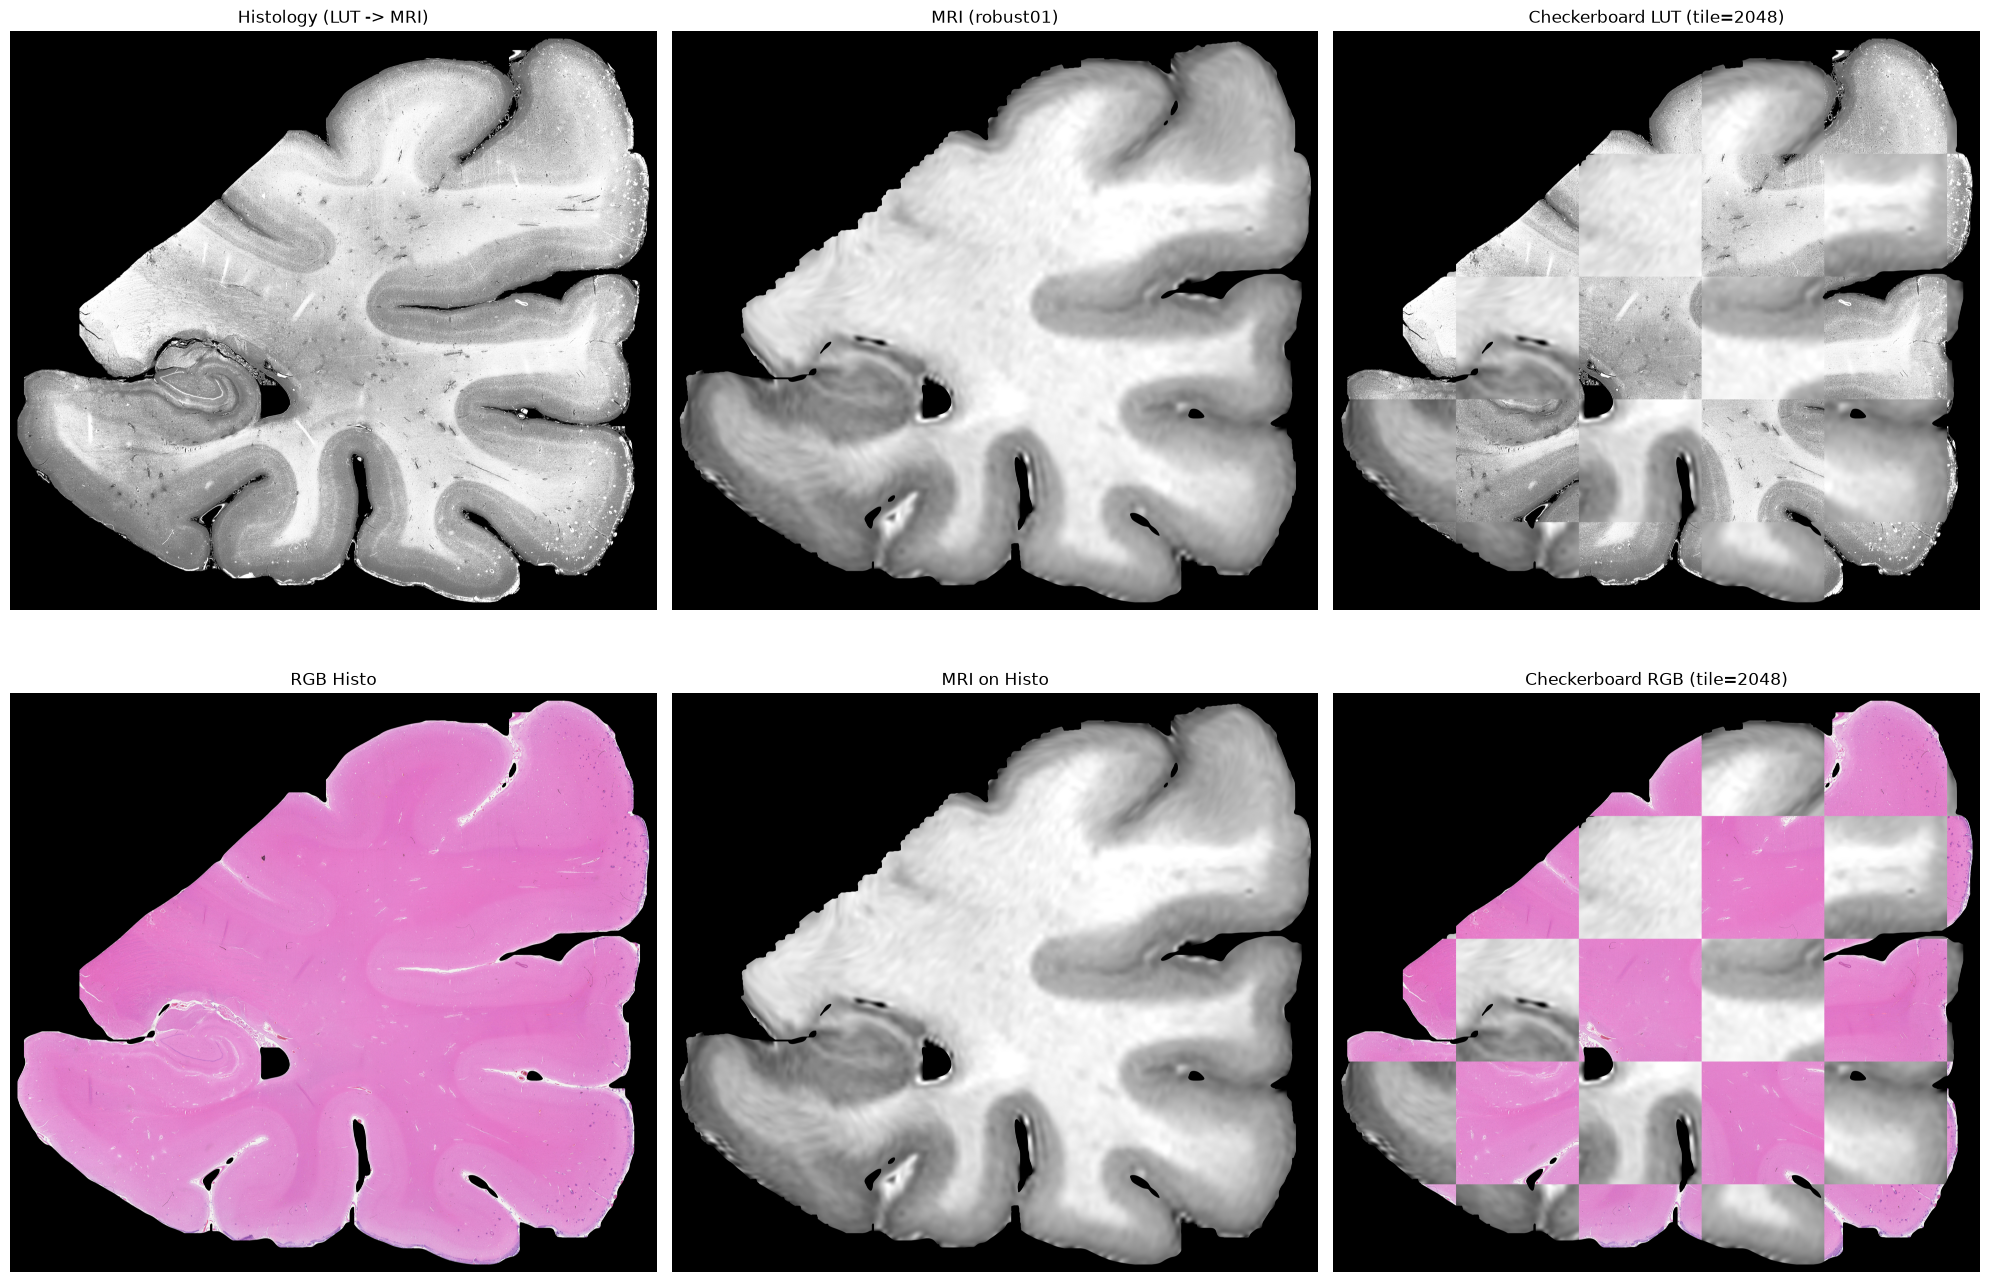

INFO histo2mri.pipeline: Saved transform grid -> ../results/demo_call_registration_pipeline/sub-NBEX919_sample-P2306_stain-HE_transform_grid.npz


INFO histo2mri.pipeline: Process finished in 187.44s


{'output_npz': '../results/demo_call_registration_pipeline/sub-NBEX919_sample-P2306_stain-HE_transform_grid.npz',
 'n_clean_matches': 10,
 'best_scale': 1.2999999523162842,
 'profile': 'default',
 'elapsed_sec': 187.44208783190697}

In [4]:
info = register_section(
    BIDS_ROOT, SUBJECT, SAMPLE, OUT_DIR,
    stain=STAIN,
    profile="default",            # "he-cblock" for H&E cerebellum blocks
    device=None,                  # None -> cuda:0 when available, else cpu
    ransac_sample_size=3,
    mri_on_histo_tile_size=2048,
    save_roi_qc=True,             # also write the three ROI QC figures
)
info

## 3. What it wrote

The returned dict names the transform it saved and a few numbers about the run. The same
folder holds the QC figures and this section's log.

In [5]:
for name in sorted(os.listdir(OUT_DIR)):
    size_mb = os.path.getsize(os.path.join(OUT_DIR, name)) / 1e6
    print(f"{size_mb:8.2f} MB  {name}")

    0.04 MB  sub-NBEX919_sample-P2306_stain-HE_histo_in_mri_space.png
    0.14 MB  sub-NBEX919_sample-P2306_stain-HE_histo_in_mri_space_all.png
    0.47 MB  sub-NBEX919_sample-P2306_stain-HE_histo_in_mri_volume.png
    0.69 MB  sub-NBEX919_sample-P2306_stain-HE_mri_on_histo.png
    8.67 MB  sub-NBEX919_sample-P2306_stain-HE_mri_on_histo_all.png
   11.93 MB  sub-NBEX919_sample-P2306_stain-HE_mri_on_histo_rgb.png
    0.00 MB  sub-NBEX919_sample-P2306_stain-HE_process.log
    0.45 MB  sub-NBEX919_sample-P2306_stain-HE_roi_3d.png
    0.38 MB  sub-NBEX919_sample-P2306_stain-HE_roi_pairs.png
    0.16 MB  sub-NBEX919_sample-P2306_stain-HE_roi_support.png
    0.65 MB  sub-NBEX919_sample-P2306_stain-HE_transform_grid.npz


## 4. QC figures

What to look at: the histology and the MRI sampled on the same sheet should show the same
structures in the same places, and their checkerboard should join across the tile edges.
The 3D panel shows where in the volume the sheet ended up.

The saved figures go up to ~6000 pixels wide, so they are shown downscaled to keep this
notebook small; open the files in `OUT_DIR` to inspect them at full resolution.

sub-NBEX919_sample-P2306_stain-HE_histo_in_mri_space_all.png  (5970x1502, shown at 1600x403)


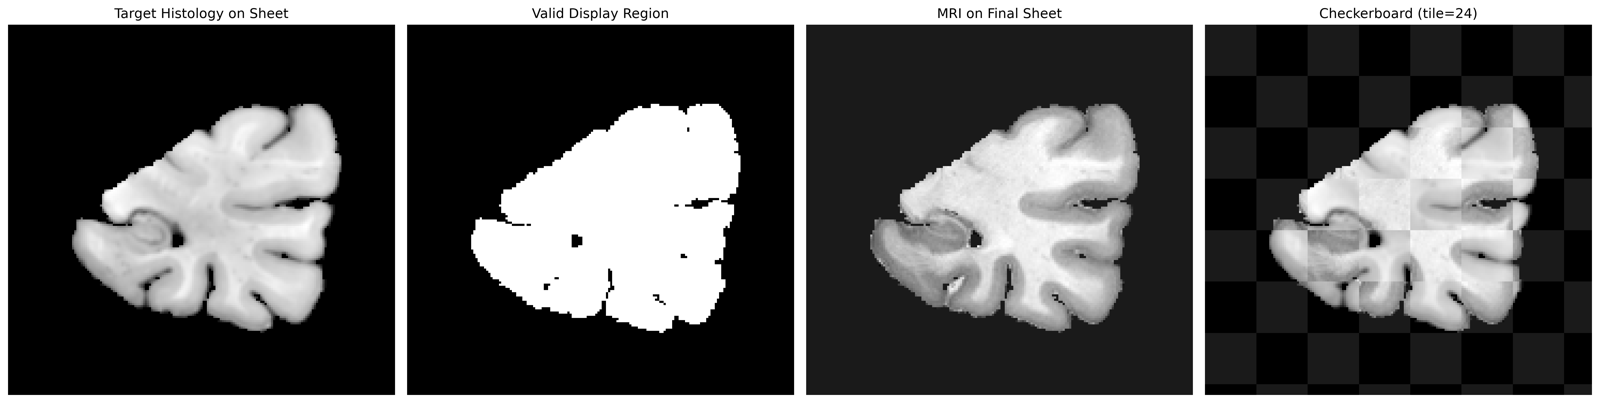

sub-NBEX919_sample-P2306_stain-HE_histo_in_mri_volume.png  (2310x616, shown at 1600x427)


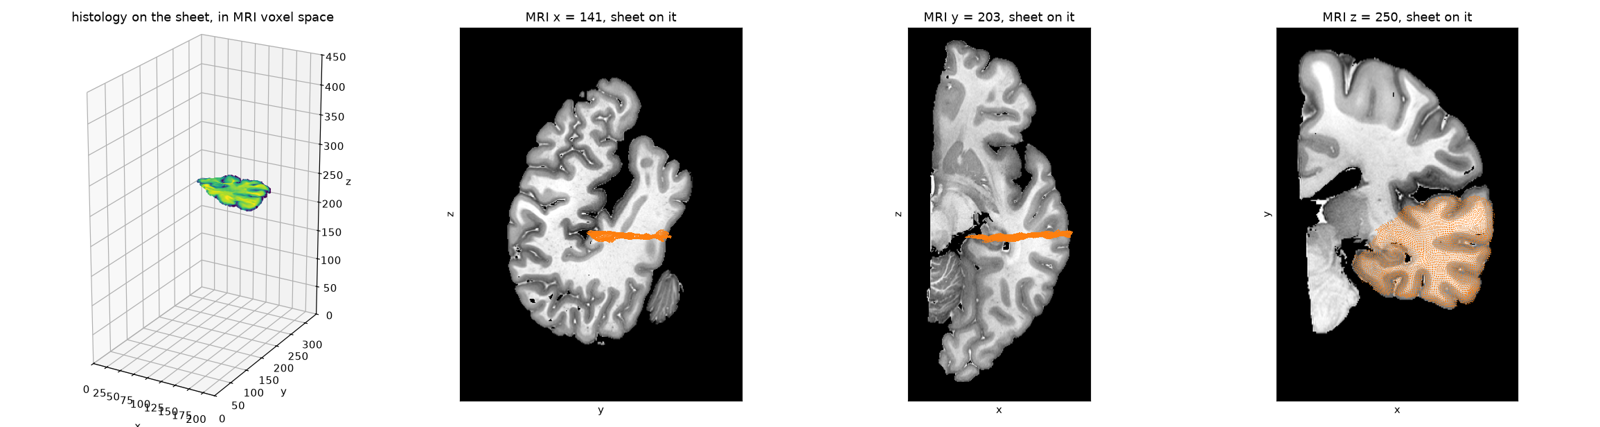

sub-NBEX919_sample-P2306_stain-HE_mri_on_histo_all.png  (5970x3585, shown at 1600x961)


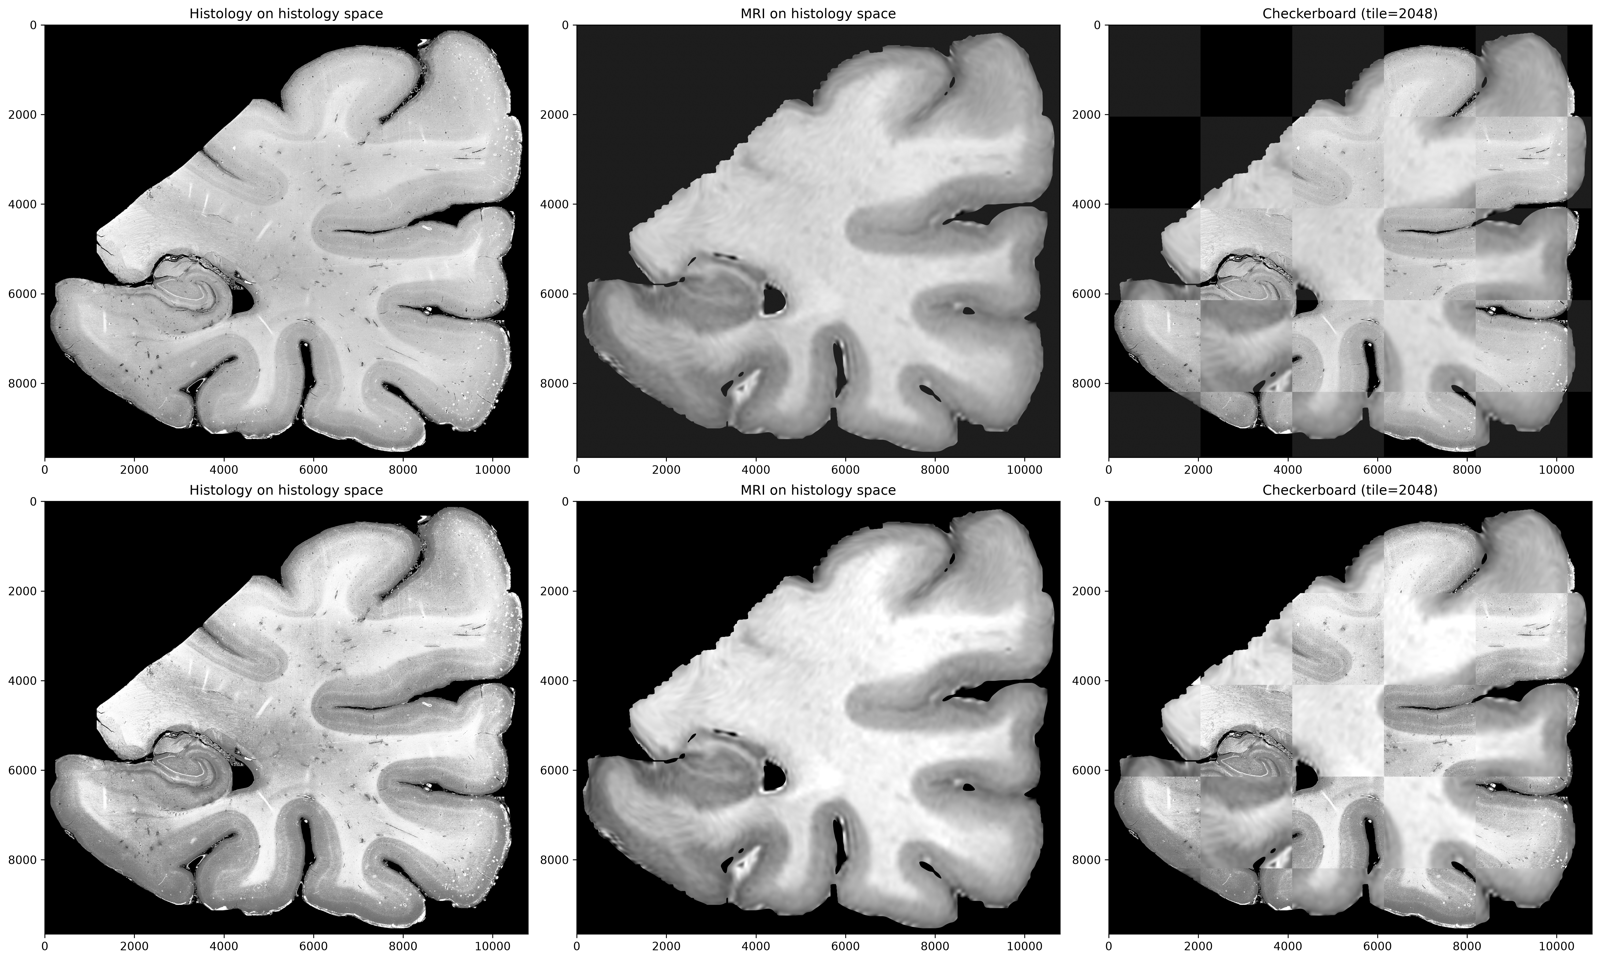

sub-NBEX919_sample-P2306_stain-HE_mri_on_histo_rgb.png  (5970x3845, shown at 1600x1030)


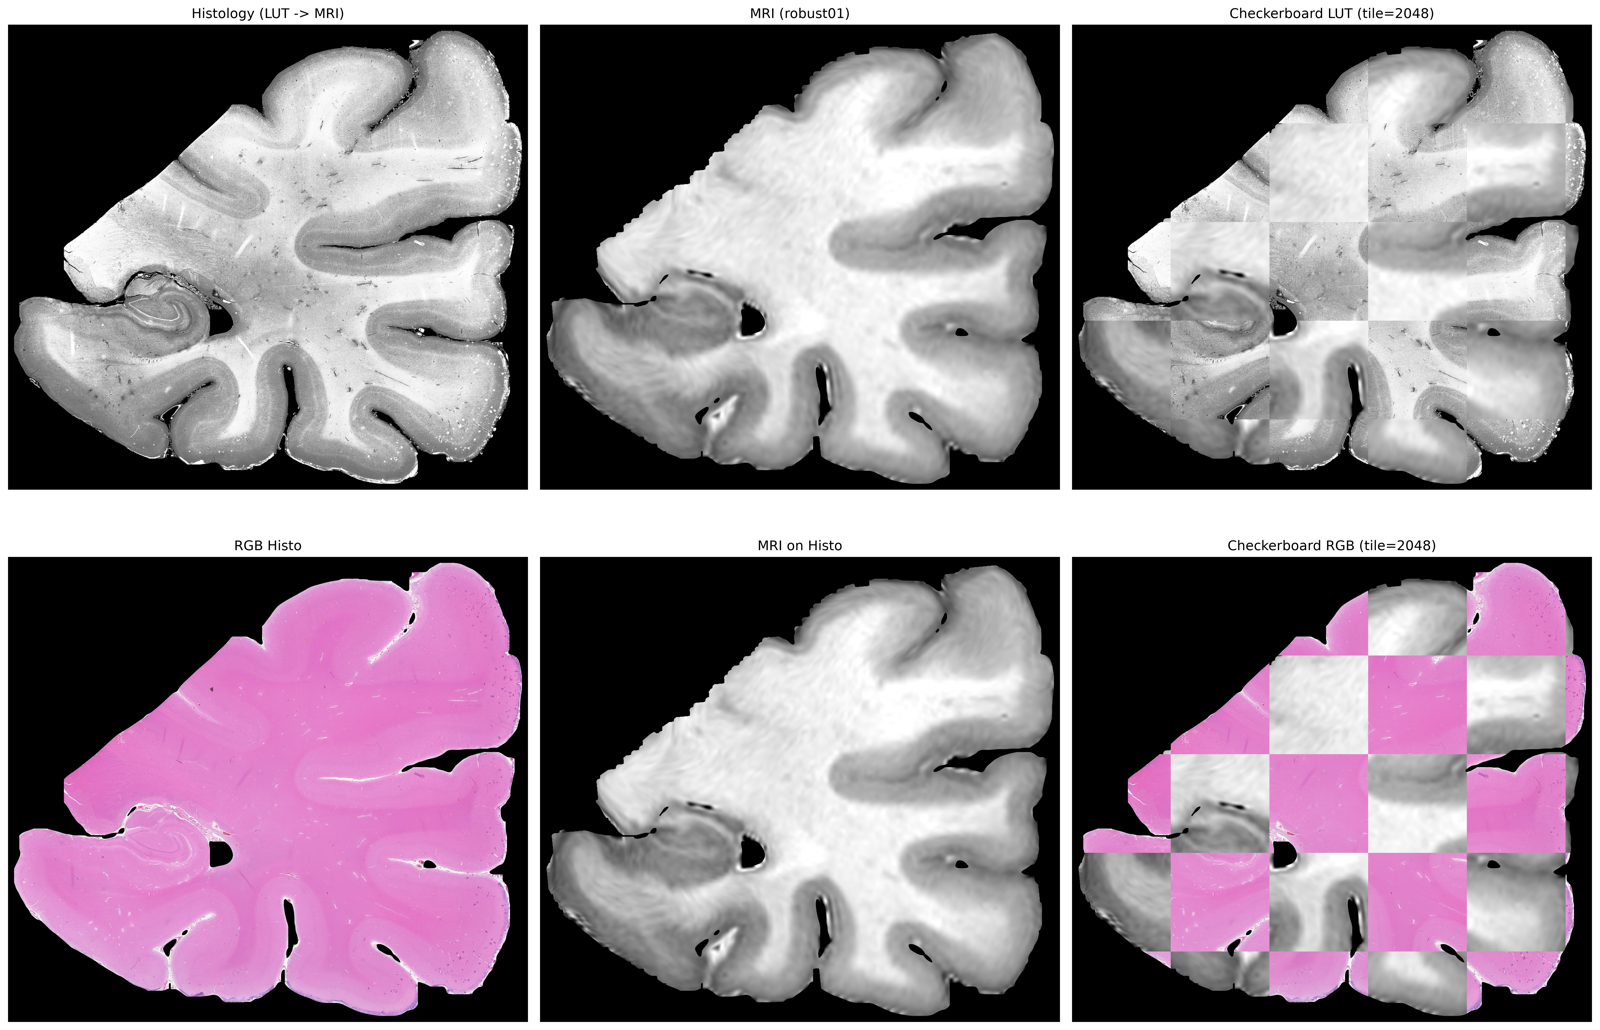

sub-NBEX919_sample-P2306_stain-HE_roi_pairs.png  (3540x2977, shown at 1600x1346)


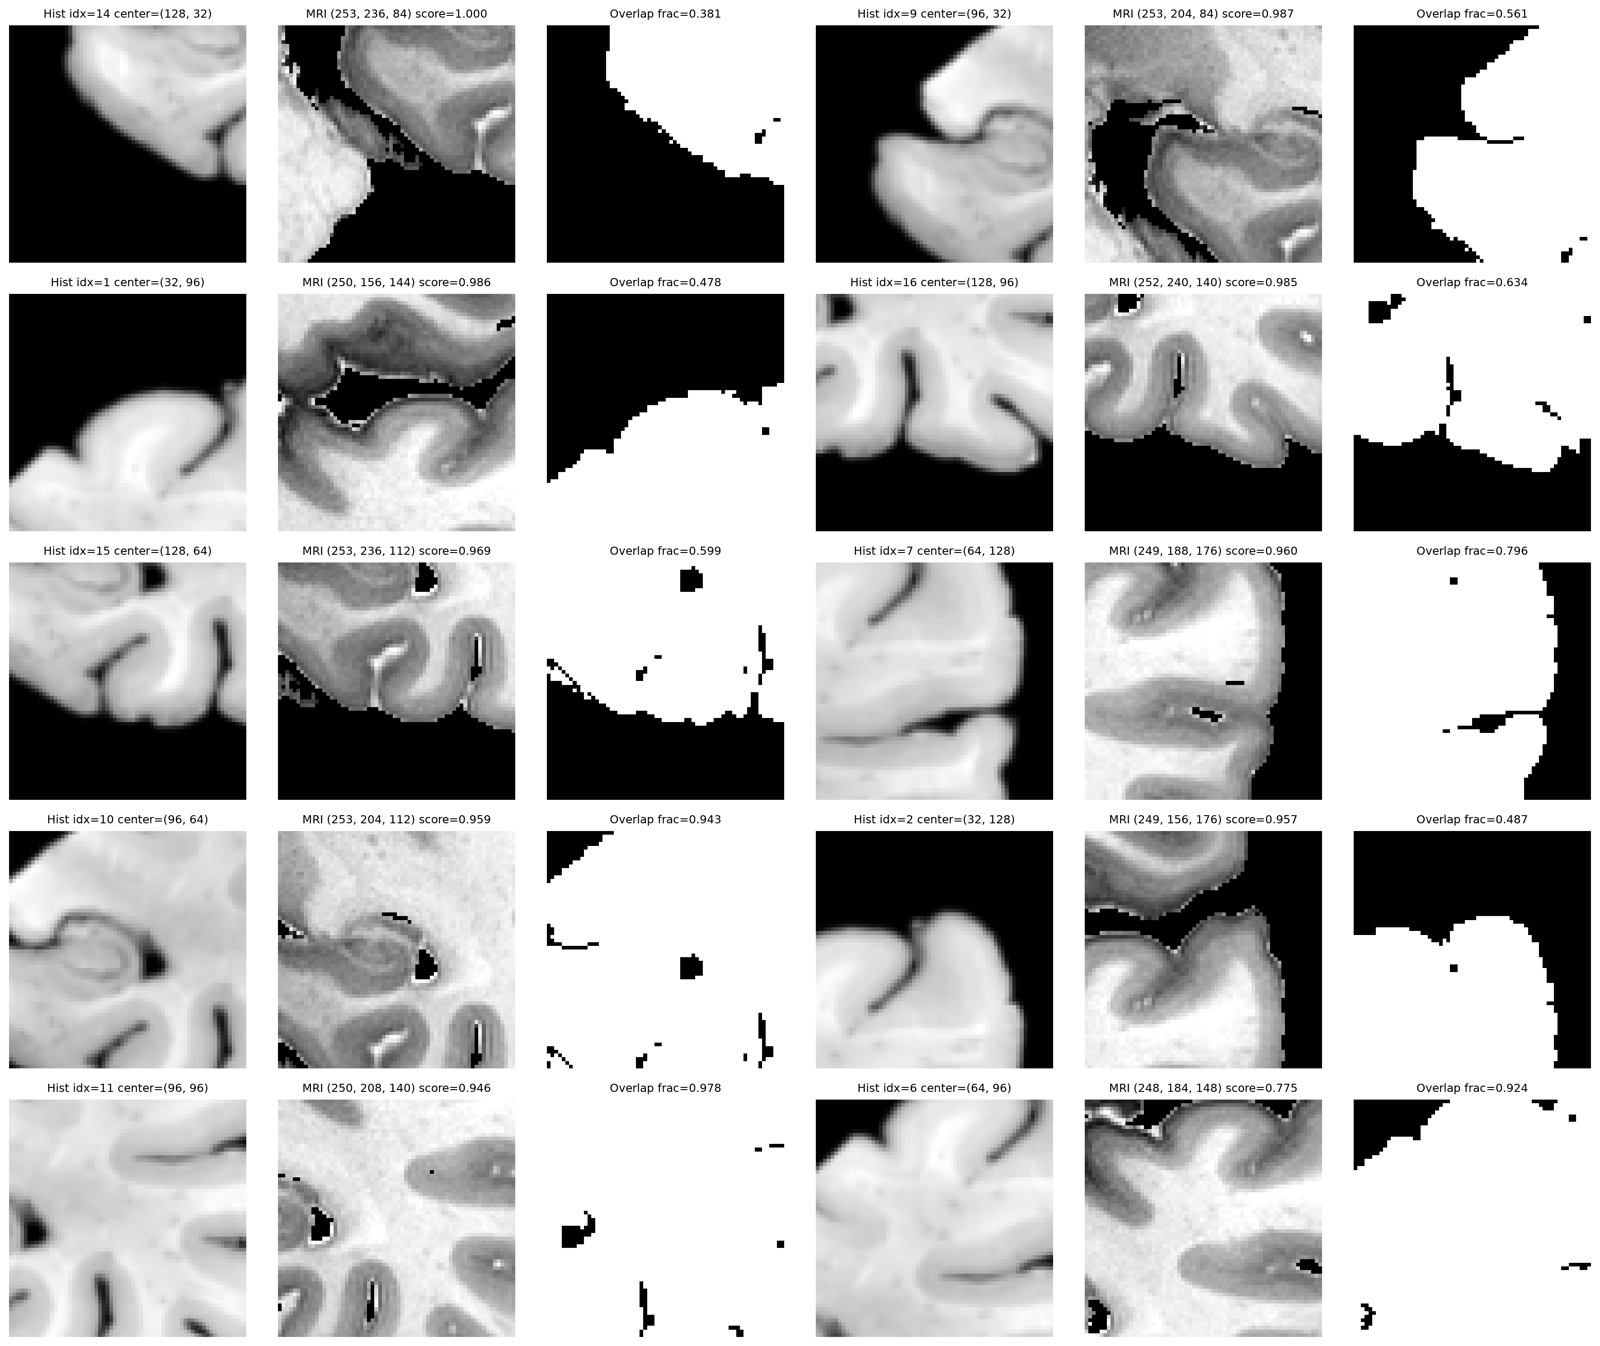

In [6]:
SECTION_ID = f"sub-{SUBJECT}_sample-{SAMPLE}_stain-{STAIN}"
PREVIEW_WIDTH = 1600

for suffix in ["histo_in_mri_space_all", "histo_in_mri_volume", "mri_on_histo_all",
               "mri_on_histo_rgb", "roi_pairs"]:
    path = os.path.join(OUT_DIR, f"{SECTION_ID}_{suffix}.png")
    if not os.path.exists(path):
        continue
    figure = Image.open(path)
    # Displaying the resized copy, not the file, is what keeps the stored output small.
    preview = figure.copy()
    preview.thumbnail((PREVIEW_WIDTH, PREVIEW_WIDTH))
    print(f"{SECTION_ID}_{suffix}.png  ({figure.width}x{figure.height}, "
          f"shown at {preview.width}x{preview.height})")
    display(preview)

## 5. The transform

`<base>_transform_grid.npz` is the result to keep: it maps a point on the slide to a point in
the volume and back, and carries the frames needed to return to the original slide and the
original MRI, so full-resolution images are regenerated from it rather than stored. The
README documents every field.

In [7]:
grid = np.load(info["output_npz"], allow_pickle=False)
for key in grid.files:
    arr = grid[key]
    print(f"{key:20s} {str(arr.dtype):10s} {arr.shape if arr.ndim else float(arr) if arr.dtype.kind == 'f' else arr}")

A_common_to_hr       float64    (4, 4)
xyz_norm_final       float32    (173, 181, 3)
xy_hist_map          float32    (173, 181, 2)
valid_surf           uint8      (173, 181)
ox_h                 float64    7.0
oy_h                 float64    3.0
G_e1                 float64    (3,)
G_e2                 float64    (3,)
mri_spacing          float64    (3,)
mri_size             int64      (3,)
mri_origin           float64    (3,)
mri_direction        float64    (9,)
mri_permute          int64      (3,)
mri_view_flip        bool       (3,)
mri_orientation      <U7        coronal
mri_canonical        <U3        LPS
mri_source           <U55       ../../data/bids/sub-NBEX919/anat/sub-NBEX919_T1w.nii.gz
histo_on_surface     float32    (173, 181)
mri_on_surface       float32    (173, 181)
A_hr_to_tif          float64    (4, 4)
crop_origin_xy       int64      (2,)
source_shape_hw      int64      (2,)
histo_source         <U107      ../../data/bids/derivatives/cleanslide/sub-NBEX919/micr/sub-NBE

## 6. The same from the command line

histo2mri is a BIDS App, so the whole dataset, or any subset of it, runs without Python:

```bash
histo2mri /path/to/bids /path/to/derivatives/histo2mri participant \
    --participant-label NBEX919 --sample-label P2306 --stain-label HE \
    --ransac-sample-size 3 --mri-on-histo-tile-size 2048
```

The command line writes the same per-section files, but into
`<output_dir>/<sub>/<base>/` and with a `dataset_description.json` at the root, whereas
`register_section` writes straight into the `out_dir` it is given.